### Installing the Necessary Dependecies

In [ ]:
%pip install pandas numpy ijson matplotlib
from google.colab import files
import os
import zipfile
import zipfile
import orjson
import re
import math
import json
import pandas as pd
from datetime import datetime

from pathlib import Path
from collections import Counter
import matplotlib.pyplot as plt
import numpy as np
import ijson

## Uploading The Dataset

In [ ]:
# useing the archive alreaday gotten fom cambridge repo
import os

# Ensure py7zr is installed to handle .7z files
try:
    import py7zr
except ImportError:
    !pip install py7zr -q
    import py7zr

uploaded = files.upload()

# Check for both .zip and .7z files
archive_path = next(
    (name for name in uploaded if name.lower().endswith(('.zip', '.7z'))),
    None
)

if archive_path is None:
    raise ValueError("Please upload the construction dataset ZIP or 7Z file.")

if archive_path.lower().endswith('.7z'):
    print(f"Processing 7z archive: {archive_path}")
    with py7zr.SevenZipFile(archive_path, mode='r') as z:
        for info in z.list():
            if info.filename.lower().endswith('.json') and not 'MACOSX' in info.filename:
                print(f"File: {info.filename}")
                print(f"Uncompressed size: {info.uncompressed / 1024**3:.4f} GB")
else:
    print(f"Processing ZIP archive: {archive_path}")
    with zipfile.ZipFile(archive_path) as z:
        json_files = [
            info for info in z.infolist()
            if info.filename.lower().endswith(".json")
            and not info.filename.startswith("__MACOSX/")
        ]
        for info in json_files:
            print(f"File: {info.filename}")
            print(f"Uncompressed size: {info.file_size / 1024**3:.4f} GB")

Saving JPF_Anonymised_Project_Data.7z to JPF_Anonymised_Project_Data.7z
Processing 7z archive: JPF_Anonymised_Project_Data.7z
File: JPF_Anonymised_Project_Data.json
Uncompressed size: 1.1993 GB


## Extraction of the Dataset Statistics

In [ ]:
import py7zr
import os

archive_path = 'JPF_Anonymised_Project_Data.7z'
print(f"Extracting {archive_path} to current directory...")

with py7zr.SevenZipFile(archive_path, mode='r') as z:
    z.extractall()

print("Extraction complete!")
# Show extracted files and their sizes
for file in os.listdir('.'):
    if file.endswith('.json'):
        size_gb = os.path.getsize(file) / (1024**3)
        print(f"Extracted: {file} ({size_gb:.4f} GB)")

Extracting JPF_Anonymised_Project_Data.7z to current directory...
Extraction complete!
Extracted: JPF_Anonymised_Project_Data.json (1.1993 GB)


In [ ]:
import ijson

json_file_path = 'JPF_Anonymised_Project_Data.json'

print("Inspecting the top-level keys of the JSON...")
try:
    with open(json_file_path, 'rb') as f:
        # ijson.kvitems allows us to parse top-level keys without loading the whole object
        parser = ijson.kvitems(f, '')
        count = 0
        for key, value in parser:
            print(f"Key: {key} | Type: {type(value)}")
            # If the value is a list or dict, print its length/keys or a preview
            if isinstance(value, list):
                print(f"  List Length: {len(value)}")
                if len(value) > 0:
                    print(f"  First item sample: {str(value[0])[:300]}...")
            elif isinstance(value, dict):
                print(f"  Dict Keys: {list(value.keys())}")
            else:
                print(f"  Value preview: {str(value)[:200]}")

            count += 1
            if count >= 10:  # Safety limit
                break
except Exception as e:
    print(f"An error occurred while streaming the JSON structure: {e}")
    print("Let's try reading the first 1000 characters to see the raw text format:")
    with open(json_file_path, 'r', encoding='utf-8') as f:
        print(f.read(1000))

Inspecting the top-level keys of the JSON...
Key: Projects | Type: <class 'dict'>
  Dict Keys: ['26256', '533', '5060', '757', '3425', '3448', '4761', '628', '33317', '6571', '15614', '1437', '54019', '74401', '4517', '3896', '3897', '3898', '219058', '10389', '7366', '10459', '2118', '11046', '10290', '26874', '31187', '2240', '3517', '3746', '3818', '4694', '5345', '6743', '7013', '7606', '8051', '8770', '9583', '9719', '10030', '10227', '10291', '11424', '11594', '11619', '11783', '11785', '12900', '12903', '12911', '12913', '13136', '13467', '14434', '14606', '15900', '16075', '16461', '16799', '28338', '31193', '33314', '38377', '40609', '44625', '45542', '45543', '45617', '45697', '45949', '46405', '46407', '52344', '56565', '22181', '4534', '2382', '1588', '1589', '1590', '1592', '1593', '1616', '1618', '1619', '1620', '1623', '1624', '1626', '1627', '1628', '1630', '1631', '1632', '1637', '1640', '1641', '1642', '1643', '1647', '1648', '1649', '1684', '1687', '1690', '1691', '1

In [ ]:
import ijson
import json

json_file_path = 'JPF_Anonymised_Project_Data.json'

print("Streaming a single project sample to inspect its internal structure...")
try:
    with open(json_file_path, 'rb') as f:
        # Targets the Projects dictionary elements
        parser = ijson.kvitems(f, 'Projects')
        for project_id, project_data in parser:
            print(f"\n--- Sample Project ID: {project_id} ---")
            print(f"Keys inside this project: {list(project_data.keys())}")

            # Let's inspect a few attributes
            for key in ['Project_Metadata', 'Activities', 'Relations']:
                if key in project_data:
                    val = project_data[key]
                    if isinstance(val, list):
                        print(f"  {key}: List of {len(val)} items. First item sample:")
                        if len(val) > 0:
                            print(f"    {json.dumps(val[0], indent=2)[:300]}...")
                    else:
                        print(f"  {key}: {json.dumps(val, indent=2)[:300]}...")

            # We only need one sample for structural understanding
            break
except Exception as e:
    print(f"An error occurred: {e}")

Streaming a single project sample to inspect its internal structure...

--- Sample Project ID: 26256 ---
Keys inside this project: ['Project_ID', 'UK_Region', 'Project_Type', 'Earliest_Project_Start_Date', 'Status_Data_Date', 'Latest_Project_Finish_Date', 'Activities', 'Work_Breakdown_Structure']
  Activities: {
  "1249674": {
    "Task_ID": "1249674",
    "Task_Type:": "1249674",
    "Activity_Description": "print issue west XXXXX stop detailed design ",
    "WBS_ID": "398615",
    "WBS_Description": "XXXXX XXXXX route works section ",
    "Original_Duration_Estimate(ODE)": "0",
    "At_Completion_Durati...


In [ ]:
output_dir = Path("construction_ml_audit")
output_dir.mkdir(exist_ok=True)

counts = Counter()
missing = Counter()
field_counts = Counter()
project_records = []
examples = []

# Identifies project entries inside the Projects mapping
project_pattern = re.compile(
    rb'^ {12}"([^"]+)": \{\s*$'
)

def to_number(value):
    try:
        if value is None or str(value).strip() == "":
            return None
        result = float(value)
        return result if math.isfinite(result) else None
    except (TypeError, ValueError):
        return None

def process_project(project_key, raw_json):
    project = orjson.loads(raw_json)
    project_id = str(project.get("Project_ID", project_key))
    activities = project.get("Activities", {})

    counts["total_projects"] += 1
    counts["total_activities"] += len(activities)

    eligible = 0
    overrun_count = 0
    no_overrun_count = 0

    for activity_id, activity in activities.items():
        field_counts.update(activity.keys())
        for field, value in activity.items():
            if value is None or value == "":
                missing[field] += 1

        original = to_number(activity.get("Original_Duration_Estimate(ODE)"))
        actual = to_number(activity.get("At_Completion_Duration"))

        if original is None:
            counts["missing_original_duration"] += 1
        elif original <= 0:
            counts["nonpositive_original_duration"] += 1

        if actual is None:
            counts["missing_actual_duration"] += 1
        elif actual < 0:
            counts["negative_actual_duration"] += 1

        if (original is not None and original > 0 and
            actual is not None and actual >= 0):
            eligible += 1
            regression_target = actual
            classification_target = int(actual > original)

            overrun_count += classification_target
            no_overrun_count += 1 - classification_target

            if len(examples) < 10:
                examples.append({
                    "Project_ID": project_id,
                    "Activity_ID": str(activity_id),
                    "Original_Duration": original,
                    "Actual_Duration": regression_target,
                    "Overrun": classification_target
                })

    counts["eligible_activities"] += eligible
    counts["overrun_activities"] += overrun_count
    counts["non_overrun_activities"] += no_overrun_count

    project_records.append({
        "Project_ID": project_id,
        "Project_Type": project.get("Project_Type"),
        "UK_Region": project.get("UK_Region"),
        "Total_Activities": len(activities),
        "Eligible_Activities": eligible,
        "Overrun_Activities": overrun_count,
        "Non_Overrun_Activities": no_overrun_count
    })

# Read directly from the extracted JSON file line-by-line
with open(json_file_path, 'rb') as file:
    current_key = None
    project_lines = []
    within_projects = False

    for line in file:
        if not within_projects:
            if line.strip() == b'"Projects": {':
                within_projects = True
            continue

        match = project_pattern.match(line)
        if match and current_key is None:
            current_key = match.group(1).decode()
            project_lines = [b"{"]
        elif current_key is not None:
            if line.startswith(b"            }") and line.strip() in (b"}", b"},"):
                project_lines.append(b"}")
                process_project(current_key, b"\n".join(project_lines))
                current_key = None
                project_lines = []
            else:
                project_lines.append(line)
        elif line.startswith(b"      }"):
            break

summary = dict(counts)
with open(output_dir / "audit_summary.json", "w") as f:
    json.dump(summary, f, indent=4)

projects_df = pd.DataFrame(project_records)
projects_df.to_csv(output_dir / "project_counts.csv", index=False)

print("DATASET AUDIT COMPLETED")
print("-" * 45)
for key, value in summary.items():
    print(f"{key}: {value:,}")

print("\nSample eligible activities:")
display(pd.DataFrame(examples))

DATASET AUDIT COMPLETED
---------------------------------------------
total_projects: 299
total_activities: 444,156
nonpositive_original_duration: 150,667
eligible_activities: 293,489
overrun_activities: 55,662
non_overrun_activities: 237,827
negative_actual_duration: 4

Sample eligible activities:


,Project_ID,Activity_ID,Original_Duration,Actual_Duration,Overrun
0,26256,1249675,25.0,25.0,0
1,26256,1249676,5.0,5.0,0
2,26256,1249677,41.0,41.0,0
3,26256,1249678,4.0,4.0,0
4,26256,1249679,30.0,30.0,0
5,26256,1249680,39.0,39.0,0
6,26256,1249682,5.0,5.0,0
7,26256,1249683,46.0,46.0,0
8,26256,1249684,68.0,68.0,0
9,26256,1249686,49.0,49.0,0


## Examine missing values and available fields

In [19]:

field_df = pd.DataFrame({
    "Field": list(field_counts.keys()),
    "Records_Present": list(field_counts.values())
})

field_df["Missing_Or_Empty"] = (
    field_df["Field"]
    .map(missing)
    .fillna(0)
    .astype(int)
)

field_df["Missing_Percent"] = (
    field_df["Missing_Or_Empty"]
    / counts["total_activities"]
    * 100
).round(2)

field_df = field_df.sort_values(
    "Missing_Percent",
    ascending=False
)

display(field_df)

field_df.to_csv(
    output_dir / "field_quality.csv",
    index=False
)


,Field,Records_Present,Missing_Or_Empty,Missing_Percent
15,Constraint_Date,444156,420999,94.79
14,Constraint_Type(if_any),444156,403717,90.90
12,Free_Float(hrs),444156,258460,58.19
26,Total_Monthly_Raindays(>=1mm),444156,199662,44.95
27,Total_Monthly_Days_of_Air_Frost,444156,199662,44.95
9,Actual_Finish_Date,444156,185804,41.83
8,Actual_Start_Date,444156,176666,39.78
21,Maximum_Monthly_Temperature(C),444156,98046,22.07
22,Minimum_Monthly_Temperature(C),444156,98046,22.07
23,Mean_Monthly_Temperature,444156,98046,22.07


### Handling Missing Values for ML
We will define a strategy to clean and prepare features from the activities, dropping columns with excessively high missing rates and imputing environmental variables while preserving a missingness indicator.

In [20]:
import pandas as pd
import numpy as np

# We will write a function to apply missing value strategies to our field dataset
def clean_and_impute_activity_data(field_df, threshold=50.0):
    # 1. Identify columns to drop (Missingness > 50%)
    cols_to_drop = field_df[field_df['Missing_Percent'] > threshold]['Field'].tolist()
    print(f"Dropping columns with > {threshold}% missing values: {cols_to_drop}\n")

    # 2. Impute weather features & add missing indicators for those around 22% missingness
    weather_cols = [
        'Total_Monthly_Rainfall(mm)',
        'Mean_Monthly_Temperature',
        'Total_Monthly_Sunshine_Hours',
        'Total_Monthly_Raindays(>=1mm)'
    ]

    print("Handling remaining missing features:")
    for col in weather_cols:
        if col in field_df['Field'].values and col not in cols_to_drop:
            print(f" - Imputing '{col}' with median and creating '{col}_is_missing' binary flag.")

clean_and_impute_activity_data(field_df)

Dropping columns with > 50.0% missing values: ['Constraint_Date', 'Constraint_Type(if_any)', 'Free_Float(hrs)']

Handling remaining missing features:
 - Imputing 'Total_Monthly_Rainfall(mm)' with median and creating 'Total_Monthly_Rainfall(mm)_is_missing' binary flag.
 - Imputing 'Mean_Monthly_Temperature' with median and creating 'Mean_Monthly_Temperature_is_missing' binary flag.
 - Imputing 'Total_Monthly_Sunshine_Hours' with median and creating 'Total_Monthly_Sunshine_Hours_is_missing' binary flag.
 - Imputing 'Total_Monthly_Raindays(>=1mm)' with median and creating 'Total_Monthly_Raindays(>=1mm)_is_missing' binary flag.


In [21]:
# Print DataFrame information
field_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 30 entries, 15 to 29
Data columns (total 4 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Field             30 non-null     object 
 1   Records_Present   30 non-null     int64  
 2   Missing_Or_Empty  30 non-null     int64  
 3   Missing_Percent   30 non-null     float64
dtypes: float64(1), int64(2), object(1)
memory usage: 1.2+ KB


In [22]:
import orjson
import pandas as pd

# Let's load activities from the first few projects to construct a sample DataFrame of the original dataset
sample_activities = []
max_sample_records = 50000

with open(json_file_path, 'rb') as file:
    current_key = None
    project_lines = []
    within_projects = False

    for line in file:
        if not within_projects:
            if line.strip() == b'"Projects": {':
                within_projects = True
            continue

        match = project_pattern.match(line)
        if match and current_key is None:
            current_key = match.group(1).decode()
            project_lines = [b"{"]
        elif current_key is not None:
            if line.startswith(b"            }") and line.strip() in (b"}", b"},"):
                project_lines.append(b"}")
                project = orjson.loads(b"\n".join(project_lines))
                activities = project.get("Activities", {})
                for act_id, act in activities.items():
                    sample_activities.append(act)
                    if len(sample_activities) >= max_sample_records:
                        break
                current_key = None
                project_lines = []
            else:
                project_lines.append(line)
        elif line.startswith(b"      }"):
            break
        if len(sample_activities) >= max_sample_records:
            break

# Convert the parsed activities into a DataFrame and show its info
original_sample_df = pd.DataFrame(sample_activities)
print(f"--- Info of the Original Dataset (Sample of {len(original_sample_df):,} records) ---")
original_sample_df.info()

--- Info of the Original Dataset (Sample of 50,000 records) ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 30 columns):
 #   Column                                                  Non-Null Count  Dtype 
---  ------                                                  --------------  ----- 
 0   Task_ID                                                 50000 non-null  object
 1   Task_Type:                                              50000 non-null  object
 2   Activity_Description                                    50000 non-null  object
 3   WBS_ID                                                  50000 non-null  object
 4   WBS_Description                                         50000 non-null  object
 5   Original_Duration_Estimate(ODE)                         50000 non-null  object
 6   At_Completion_Duration                                  50000 non-null  object
 7   Duration_Growth_Percentage(Y_values)                    50000 non-

In [23]:
original_sample_df.head()

,Task_ID,Task_Type:,Activity_Description,WBS_ID,WBS_Description,Original_Duration_Estimate(ODE),At_Completion_Duration,Duration_Growth_Percentage(Y_values),Actual_Start_Date,Actual_Finish_Date,...,GMM_Topic_Classification,Maximum_Monthly_Temperature(C),Minimum_Monthly_Temperature(C),Mean_Monthly_Temperature,Total_Monthly_Sunshine_Hours,Total_Monthly_Rainfall(mm),Total_Monthly_Raindays(>=1mm),Total_Monthly_Days_of_Air_Frost,Market_Conditions_at_Project_Start(±st.dev._from_mean),Activity_Relationships
0,1249674,1249674,print issue west XXXXX stop detailed design,398615,XXXXX XXXXX route works section,0,0,0.0,,,...,1,6,10.6,211.9,40.6,6,0.5,0.5,3.123,"{'1253310': {'Predecessor_ID': '1253310', 'Rel..."
1,1249675,1249675,mobilisation,398554,key milestones,25,25,0.0,2010-03-29 00:00,2010-04-23 00:00,...,5,1.2,5,118.1,82.8,11.8,12.1,12.1,3.123,"{'1250179': {'Predecessor_ID': '1250179', 'Rel..."
2,1249676,1249676,excavate for stop foundations,400362,XXXXX stop,5,5,0.0,,,...,0,5.8,8.7,65.1,86,12.8,1.4,1.4,3.123,"{'1249674': {'Predecessor_ID': '1249674', 'Rel..."
3,1249677,1249677,stop XXXXX post trackwork,400362,XXXXX stop,41,41,0.0,,,...,0,2.8,6.4,120.7,128.1,17.5,5.3,5.3,3.123,"{'1249676': {'Predecessor_ID': '1249676', 'Rel..."
4,1249678,1249678,print issue XXXXX XXXXX stop detailed design,398617,XXXXX XXXXX route works section three XXXXX XX...,4,4,0.0,,,...,1,3.1,5.7,49.7,154.4,17.7,3.1,3.1,3.123,"{'1251429': {'Predecessor_ID': '1251429', 'Rel..."


In [24]:
original_sample_df.columns

Index(['Task_ID', 'Task_Type:', 'Activity_Description', 'WBS_ID',
       'WBS_Description', 'Original_Duration_Estimate(ODE)',
       'At_Completion_Duration', 'Duration_Growth_Percentage(Y_values)',
       'Actual_Start_Date', 'Actual_Finish_Date', 'Planned_Start_Date',
       'Planned_Finish_Date', 'Free_Float(hrs)', 'Total_Float(d)',
       'Constraint_Type(if_any)', 'Constraint_Date', 'Calendar_ID',
       'Physical_Percent_Complete', 'Concurrent_Activity_Count',
       'Task_Position_(percentage_through_project)',
       'GMM_Topic_Classification', 'Maximum_Monthly_Temperature(C)',
       'Minimum_Monthly_Temperature(C)', 'Mean_Monthly_Temperature',
       'Total_Monthly_Sunshine_Hours', 'Total_Monthly_Rainfall(mm)',
       'Total_Monthly_Raindays(>=1mm)', 'Total_Monthly_Days_of_Air_Frost',
       'Market_Conditions_at_Project_Start(±st.dev._from_mean)',
       'Activity_Relationships'],
      dtype='object')

In [25]:
original_sample_df.isnull().sum()

,0
Task_ID,0
Task_Type:,0
Activity_Description,0
WBS_ID,0
WBS_Description,0
Original_Duration_Estimate(ODE),0
At_Completion_Duration,0
Duration_Growth_Percentage(Y_values),0
Actual_Start_Date,0
Actual_Finish_Date,0


## Visualise the distribution of activity overruns

Eligible records: 293,489
Overruns: 55,662
No overruns: 237,827
Overrun rate: 18.97%


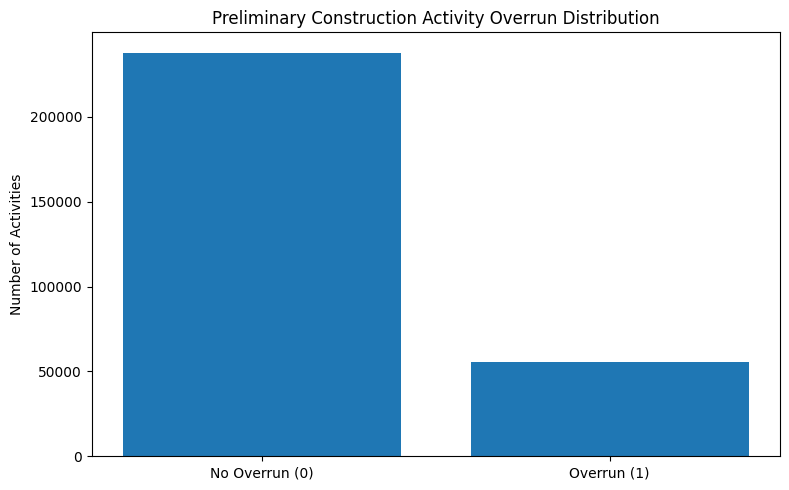

In [26]:


overrun = counts["overrun_activities"]
non_overrun = counts["non_overrun_activities"]

total = overrun + non_overrun

print(f"Eligible records: {total:,}")
print(f"Overruns: {overrun:,}")
print(f"No overruns: {non_overrun:,}")

if total > 0:
    print(f"Overrun rate: {overrun / total:.2%}")

    plt.figure(figsize=(8, 5))

    plt.bar(
        ["No Overrun (0)", "Overrun (1)"],
        [non_overrun, overrun]
    )

    plt.title("Preliminary Construction Activity Overrun Distribution")
    plt.ylabel("Number of Activities")
    plt.tight_layout()
    plt.show()

The height difference between the two bars shows a strong class imbalance. About 4 out of every 5 eligible construction activities are completed on time or early, while only about 1 out of 5 experiences a duration overrun.

PROJECT-LEVEL DATASET SUMMARY


,Project_ID,Project_Type,UK_Region,Total_Activities,Eligible_Activities,Overrun_Activities,Non_Overrun_Activities
0,26256,Light Rail - Overground,North West England/North Wales,7864,6353,18,6335
1,533,Waste Water Treatment,South East England and South Central England,11971,7256,2450,4806
2,5060,Highways,North West England/North Wales,1496,850,239,611
3,757,Rail,South East England and South Central England,1198,769,0,769
4,3425,Power Generation - Renewables,North West England/North Wales,512,213,86,127
5,3448,Electical Networks,East Anglia,2063,1363,140,1223
6,4761,Power Generation - Coal,South East England and South Central England,176,137,0,137
7,628,Clean Water Networks,North West England/North Wales,1620,1158,0,1158
8,33317,Light Rail - Overground,North West England/North Wales,506,356,36,320
9,6571,Highways,North West England/North Wales,424,209,64,145



Descriptive statistics:


,Total_Activities,Eligible_Activities,Overrun_Activities,Non_Overrun_Activities
count,299.000000,299.000000,299.000000,299.000000
mean,1485.471572,981.568562,186.160535,795.408027
std,3973.311197,2746.869534,607.259766,2241.802413
min,10.000000,0.000000,0.000000,0.000000
25%,31.000000,15.000000,2.000000,13.000000
50%,93.000000,51.000000,6.000000,43.000000
75%,732.000000,391.000000,16.500000,359.500000
max,34407.000000,24904.000000,4612.000000,20785.000000


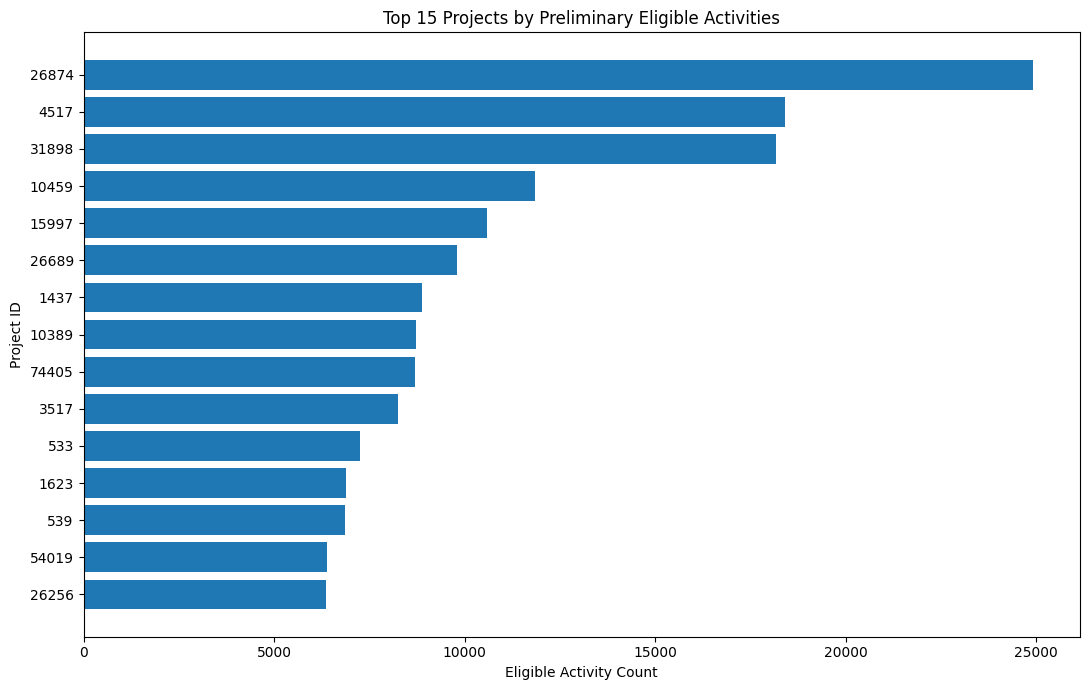

In [27]:
print("PROJECT-LEVEL DATASET SUMMARY")

# display top-5 Rows
display(projects_df.head(10))

# display the descriptive statistics
print("\nDescriptive statistics:")
display(projects_df.describe())

# Top-15 Project by Eligible_Activities
top_projects = projects_df.nlargest(
    15, "Eligible_Activities"
).sort_values("Eligible_Activities")

plt.figure(figsize=(11, 7))

plt.barh(
    top_projects["Project_ID"].astype(str),
    top_projects["Eligible_Activities"]
)

plt.xlabel("Eligible Activity Count")
plt.ylabel("Project ID")
plt.title("Top 15 Projects by Preliminary Eligible Activities")
plt.tight_layout()
plt.show()

### Download audit results

In [28]:
import shutil
from google.colab import files

shutil.make_archive(
    "construction_ml_audit",
    "zip",
    output_dir
)

files.download("construction_ml_audit.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>